In [1]:
# 
# --- plot ERW trajectories and the ag maps we derive from them 
# 
import os

import cmocean as cmo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# --- read in data 
RUNNAMES = [ 
    'exe_central1p5', 'exe_central2p0', 'exe_limBio1p5', 'exe_lowCCS1p5',
    'exe_lowCDR1p5', 'exe_noBiochar1p5', 'exe_noWeathering1p5',
    'exe_ref1p5', 'exe_techBehaviorChange1p5', 'exe_techBehaviorChange2p0', 
]

# ************************************************
# --- GCAM outputs
run_format = 'one-cell-per-region'
deg_resolution = 1
dfdict = {}
for RUNNAME in RUNNAMES:
    gcam_dir = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{run_format}/{RUNNAME}'
    gcam_fn = f'annual_rockflx_densest-ag-region_{deg_resolution}deg.pkl'
    # [ read in ]
    tdf = pd.read_pickle(os.path.join(gcam_dir, gcam_fn))
    # [ add to dict ]
    dfdict[RUNNAME] = tdf

# ************************************************
# --- example derived ag map
RUNNAME_EXAMPLE = 'exe_central1p5'
run_format = 'one-cell-per-region'
deg_resolution = 1
gcam_dir = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{run_format}/{RUNNAME_EXAMPLE}'
gcam_fn = f'cropland+gcamRegions_time_{deg_resolution}deg.zarr'
# [ read in ]
dsag = xr.open_zarr(os.path.join(gcam_dir, gcam_fn))

## Calculate global sums 

In [2]:
# --- use separate dict for globals
dfdict_globs = {}
for key, val in dfdict.items():
    # --- compute global GCAM CDR 
    dfdict_globs[key] = (
        val.groupby("time", as_index=False)["gcam_gross_cdr_mtCO2"]
        .sum()
        .assign(region="globe")
    )

## Plot cases 

### Global removal rates --- all cases black lines 

In [3]:
dfdict_globs.keys()

dict_keys(['exe_central1p5', 'exe_central2p0', 'exe_limBio1p5', 'exe_lowCCS1p5', 'exe_lowCDR1p5', 'exe_noBiochar1p5', 'exe_noWeathering1p5', 'exe_ref1p5', 'exe_techBehaviorChange1p5', 'exe_techBehaviorChange2p0'])

(2020.0, 2100.0)

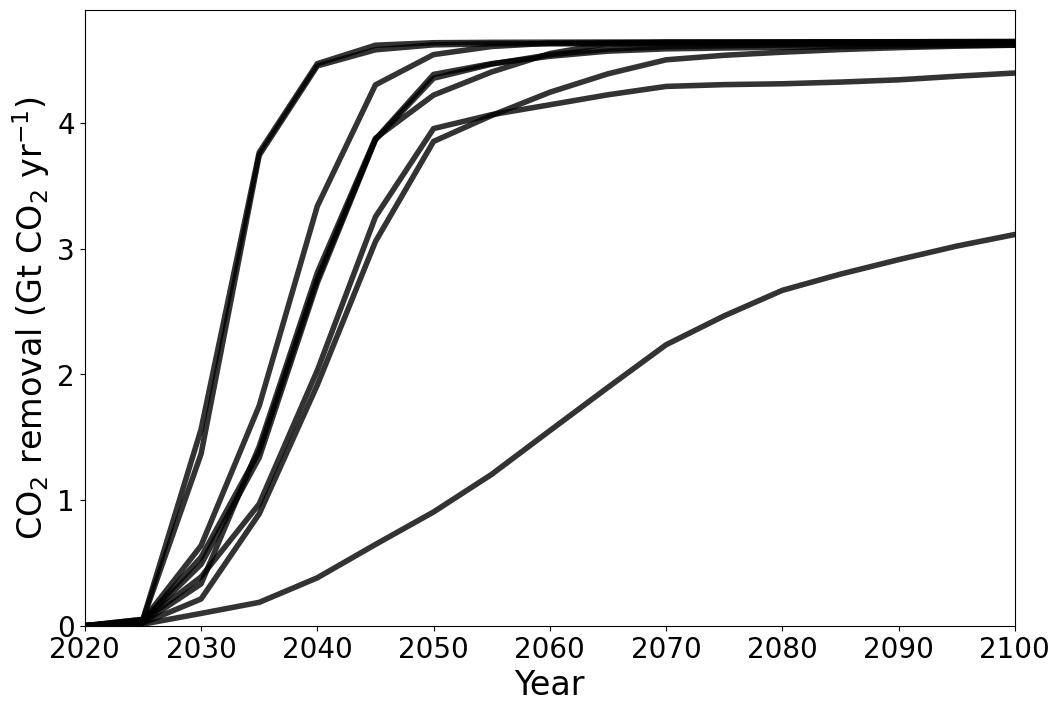

In [13]:
# ---------------------------------
# [ aesthetics ]
# colors
line_cmap = cmo.cm.rain_r # Choose a cmocean colormap
cmap_start = 0.1
cmap_end = 0.9
allcases_col = 'black'
allcases_alph = 0.8
# lines
ls_case = 8
ls_bg = 4
# legend
legend_on = False
# fontsizes 
fs_ticks = 20
fs_lab = 24
fs_legend = 18
# ---------------------------------
casesonly = False
# cases_to_plot = ['exe_central1p5', 'exe_lowCDR1p5', 'exe_noWeathering1p5', 'exe_techBehaviorChange1p5']
cases_to_plot = [
    'exe_central2p0', 'exe_central1p5', 'exe_lowCDR1p5', 'exe_noWeathering1p5', 'exe_techBehaviorChange1p5'
]
cases_to_omit = ['exe_ref1p5'] # ref is no policy, and Fuhrman omits it from their figures
casenames = {'exe_central2p0': 'Main (2°C)',
    'exe_central1p5': 'Main', 
             'exe_lowCDR1p5': 'Lower CDR deployment', 
             'exe_noWeathering1p5': 'High-cost ERW', 
             'exe_techBehaviorChange1p5': 'Ambitious behavior change'}
# set cols
n_lines = len(cases_to_plot)
colors = [line_cmap(i) for i in np.linspace(cmap_start, cmap_end, n_lines)]  # spaced colors
order = [1, 2, 3, 0]
colors_sorted = [colors[i] for i in order]

col_idx = 0
plt.figure(figsize=(12,8))
if casesonly:
    for key, df in dfdict_globs.items(): # all cases
        if key in cases_to_omit: continue
        plt.plot(df['time'], -1*df['gcam_gross_cdr_mtCO2']/1e3, c='lightgray', linewidth=ls_bg)
    for key, df in dfdict_globs.items(): # just the ones we want to highlight
        if key in cases_to_omit: continue
        if key in cases_to_plot:
            print(key)
            # plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, label=casenames[key], linewidth = ls_case, c=colors_sorted[col_idx])
            plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, label=casenames[key], linewidth = ls_case)
            col_idx += 1
else:
    for key, df in dfdict_globs.items():
        if key in cases_to_omit: continue
        plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, linewidth=ls_bg, c=allcases_col, alpha=allcases_alph)

if legend_on: 
    handles, labels = plt.gca().get_legend_handles_labels()
    # reorder handles and labels
    order_leg = [3,0,1,2,4]
    handles = [handles[i] for i in order_leg]
    labels  = [labels[i] for i in order_leg]
    # draw the legend in the new order
    plt.legend(handles, labels, fontsize=fs_legend)
plt.tick_params(labelsize=fs_ticks)
plt.ylabel(r"CO$_2$ removal (Gt CO$_2$ yr$^{-1}$)", fontsize=fs_lab)
plt.xlabel("Year", fontsize=fs_lab)
plt.ylim(0,4.9)
plt.xlim(2020, 2100)

#### Global removal rates — select cases 

(2020.0, 2100.0)

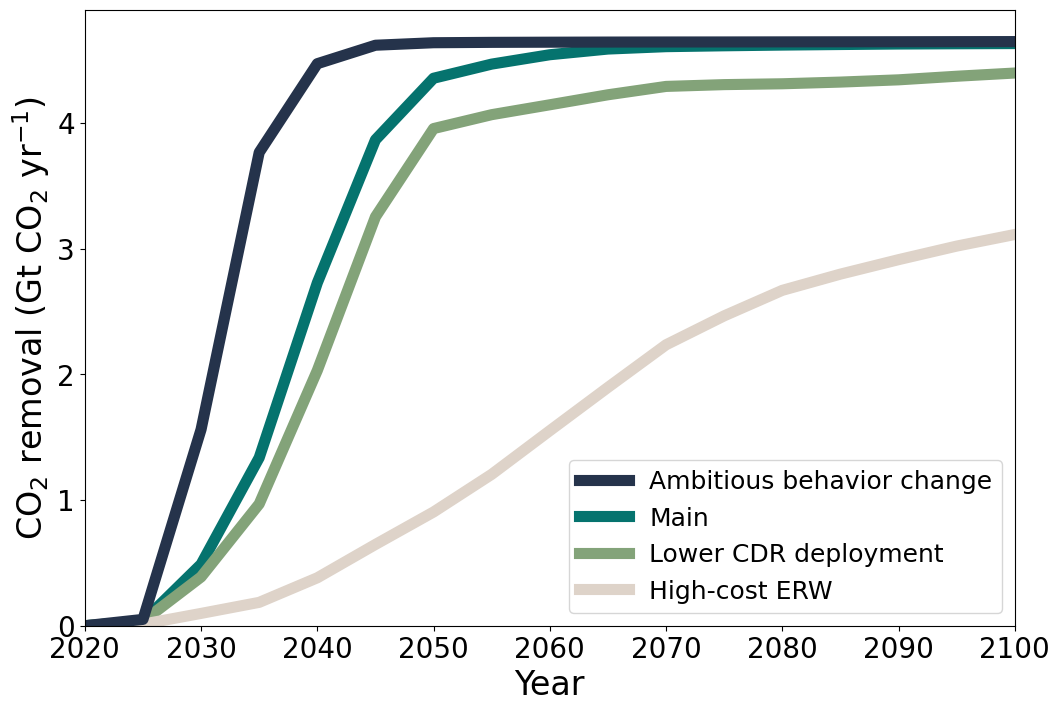

In [254]:
# ---------------------------------
# [ aesthetics ]
# colors
line_cmap = cmo.cm.rain_r # Choose a cmocean colormap
cmap_start = 0.1
cmap_end = 0.9
allcases_col = 'black'
allcases_alph = 0.8
# lines
ls_case = 8
ls_bg = 4
# legend
legend_on = True
# fontsizes 
fs_ticks = 20
fs_lab = 24
fs_legend = 18
# ---------------------------------
casesonly = True
cases_to_plot = ['exe_central1p5', 'exe_lowCDR1p5', 'exe_noWeathering1p5', 'exe_techBehaviorChange1p5']
cases_to_omit = ['exe_ref1p5'] # ref is no policy, and Fuhrman omits it from their figures
casenames = {'exe_central1p5': 'Main', 
             'exe_lowCDR1p5': 'Lower CDR deployment', 
             'exe_noWeathering1p5': 'High-cost ERW', 
             'exe_techBehaviorChange1p5': 'Ambitious behavior change'}
# set cols
n_lines = len(cases_to_plot)
colors = [line_cmap(i) for i in np.linspace(cmap_start, cmap_end, n_lines)]  # spaced colors
order = [1, 2, 3, 0]
colors_sorted = [colors[i] for i in order]

col_idx = 0
plt.figure(figsize=(12,8))
if casesonly:
    for key, df in dfdict_globs.items(): # all cases
        if key in cases_to_omit: continue
        plt.plot(df['time'], -1*df['gcam_gross_cdr_mtCO2']/1e3, c='lightgray', linewidth=ls_bg)
    for key, df in dfdict_globs.items(): # just the ones we want to highlight
        if key in cases_to_omit: continue
        if key in cases_to_plot:
            plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, label=casenames[key], linewidth = ls_case, c=colors_sorted[col_idx])
            col_idx += 1
else:
    for key, df in dfdict_globs.items():
        if key in cases_to_omit: continue
        plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, linewidth=ls_bg, c=allcases_col, alpha=allcases_alph)

if legend_on: 
    handles, labels = plt.gca().get_legend_handles_labels()
    # reorder handles and labels
    order_leg = [3,0,1,2]
    handles = [handles[i] for i in order_leg]
    labels  = [labels[i] for i in order_leg]
    # draw the legend in the new order
    plt.legend(handles, labels, fontsize=fs_legend)
plt.tick_params(labelsize=fs_ticks)
plt.ylabel(r"CO$_2$ removal (Gt CO$_2$ yr$^{-1}$)", fontsize=fs_lab)
plt.xlabel("Year", fontsize=fs_lab)
plt.ylim(0,4.9)
plt.xlim(2020, 2100)

## Plot highlight main + high-cost ERW

(0.0, 4.9)

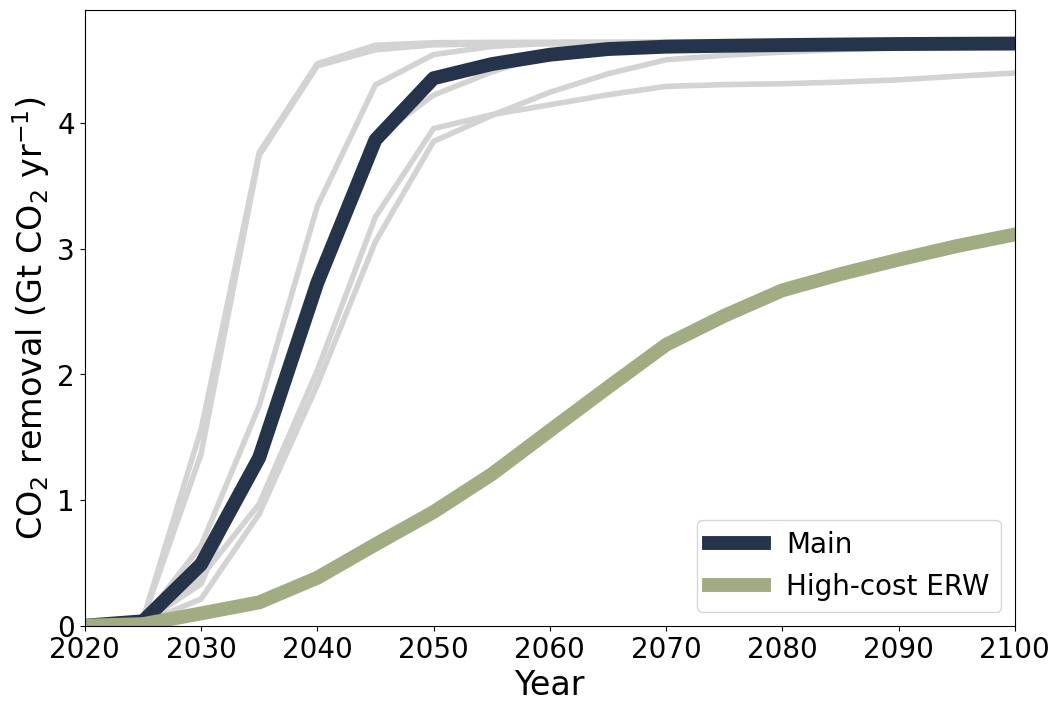

In [258]:
# ---------------------------------
# [ aesthetics ]
# colors
line_cmap = cmo.cm.rain_r # Choose a cmocean colormap
cmap_start = 0.1
cmap_end = 0.7
allcases_col = 'black'
allcases_alph = 0.8
# lines
ls_case = 10
ls_bg = 4
# legend
legend_on = True
# fontsizes 
fs_ticks = 20
fs_lab = 24
fs_legend = 20
# ---------------------------------
casesonly = True
cases_to_plot = ['exe_central1p5', 'exe_noWeathering1p5']
cases_to_omit = ['exe_ref1p5'] # ref is no policy, and Fuhrman omits it from their figures
casenames = {'exe_central1p5': 'Main', 
             'exe_lowCDR1p5': 'Lower CDR deployment', 
             'exe_noWeathering1p5': 'High-cost ERW', 
             'exe_techBehaviorChange1p5': 'Ambitious behavior change'}
# set cols
n_lines = len(cases_to_plot)
colors = [line_cmap(i) for i in np.linspace(cmap_start, cmap_end, n_lines)]  # spaced colors
order = [0,1]
colors_sorted = [colors[i] for i in order]

col_idx = 0
plt.figure(figsize=(12,8))
if casesonly:
    for key, df in dfdict_globs.items(): # all cases
        if key in cases_to_omit: continue
        plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, c='lightgray', linewidth=ls_bg)
    for key, df in dfdict_globs.items(): # just the ones we want to highlight
        if key in cases_to_omit: continue
        if key in cases_to_plot:
            plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, label=casenames[key], linewidth = ls_case, c=colors_sorted[col_idx])
            col_idx += 1
else:
    for key, df in dfdict_globs.items():
        if key in cases_to_omit: continue
        plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, linewidth=ls_bg, c=allcases_col, alpha=allcases_alph)

if legend_on: 
    handles, labels = plt.gca().get_legend_handles_labels()
    # reorder handles and labels
    order_leg = [0,1]
    handles = [handles[i] for i in order_leg]
    labels  = [labels[i] for i in order_leg]
    # draw the legend in the new order
    plt.legend(handles, labels, fontsize=fs_legend)
plt.tick_params(labelsize=fs_ticks)
plt.ylabel(r"CO$_2$ removal (Gt CO$_2$ yr$^{-1}$)", fontsize=fs_lab)
plt.xlabel("Year", fontsize=fs_lab)
plt.xlim(2020, 2100)
plt.ylim(0,4.9)

## Plot highlight high-cost ERW

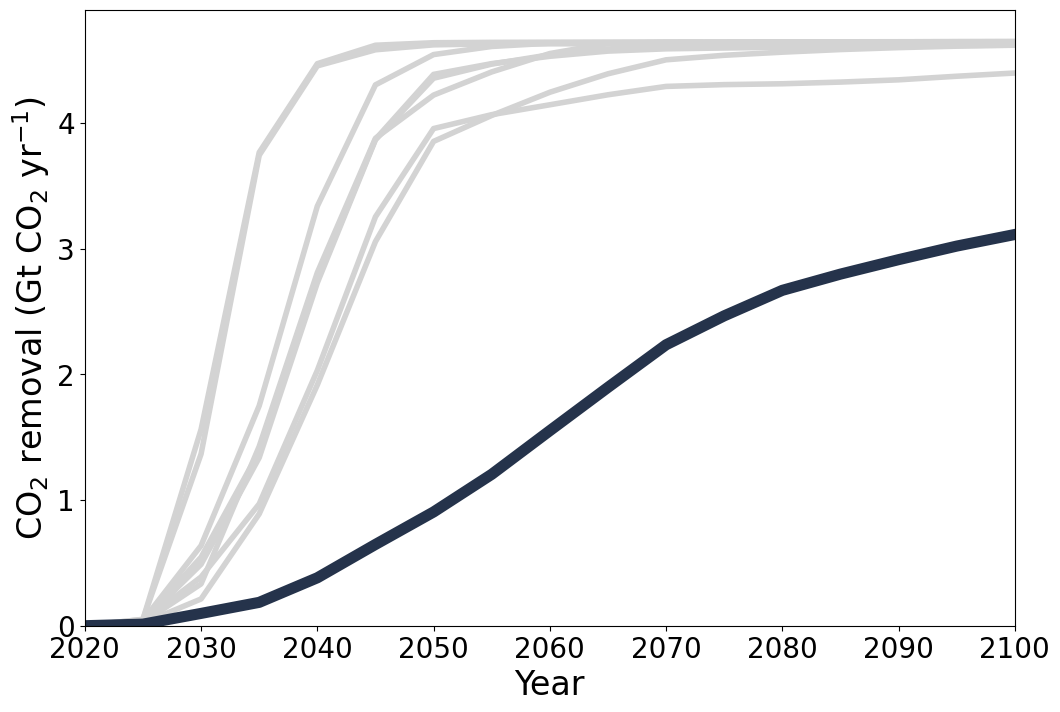

In [257]:
# ---------------------------------
# [ aesthetics ]
# colors
line_cmap = cmo.cm.rain_r # Choose a cmocean colormap
cmap_start = 0.1
cmap_end = 0.9
allcases_col = 'black'
allcases_alph = 0.8
# lines
ls_case = 8
ls_bg = 4
# legend
legend_on = False
# fontsizes 
fs_ticks = 20
fs_lab = 24
fs_legend = 18
# ---------------------------------
casesonly = True
cases_to_plot = ['exe_noWeathering1p5']
cases_to_omit = ['exe_ref1p5'] # ref is no policy, and Fuhrman omits it from their figures
casenames = {'exe_central1p5': 'Main', 
             'exe_lowCDR1p5': 'Lower CDR deployment', 
             'exe_noWeathering1p5': 'High-cost ERW', 
             'exe_techBehaviorChange1p5': 'Ambitious behavior change'}
# set cols
n_lines = len(cases_to_plot)
colors = [line_cmap(i) for i in np.linspace(cmap_start, cmap_end, n_lines)]  # spaced colors
order = [0]
colors_sorted = [colors[i] for i in order]

col_idx = 0
plt.figure(figsize=(12,8))
if casesonly:
    for key, df in dfdict_globs.items(): # all cases
        if key in cases_to_omit: continue
        plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, c='lightgray', linewidth=ls_bg)
    for key, df in dfdict_globs.items(): # just the ones we want to highlight
        if key in cases_to_omit: continue
        if key in cases_to_plot:
            plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, label=casenames[key], linewidth = ls_case, c=colors_sorted[col_idx])
            col_idx += 1
else:
    for key, df in dfdict_globs.items():
        if key in cases_to_omit: continue
        plt.plot(df['time'], df['gcam_gross_cdr_mtCO2']/1e3, linewidth=ls_bg, c=allcases_col, alpha=allcases_alph)

if legend_on: 
    handles, labels = plt.gca().get_legend_handles_labels()
    # reorder handles and labels
    order_leg = [0]
    handles = [handles[i] for i in order_leg]
    labels  = [labels[i] for i in order_leg]
    # draw the legend in the new order
    plt.legend(handles, labels, fontsize=fs_legend)
plt.tick_params(labelsize=fs_ticks)
plt.ylabel(r"CO$_2$ removal (Gt CO$_2$ yr$^{-1}$)", fontsize=fs_lab)
plt.xlabel("Year", fontsize=fs_lab)
plt.xlim(2020, 2100)
plt.ylim(0,4.9);

## Plot rock fluxes

(2020.0, 2100.0)

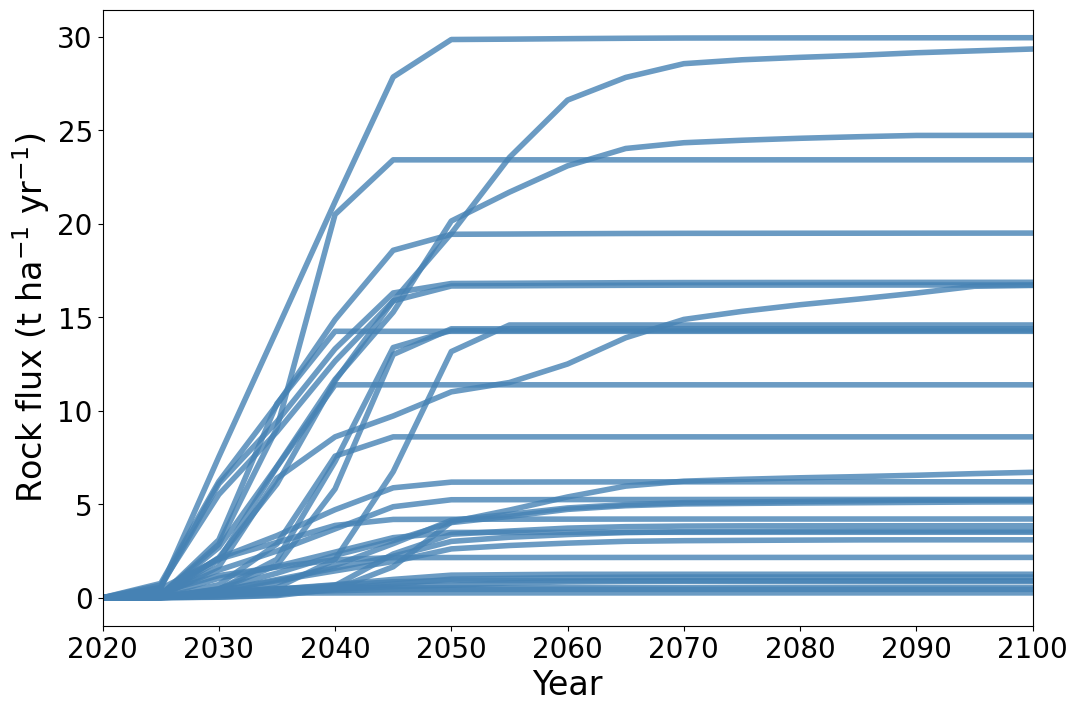

In [106]:
# ---------------------------------
# [ aesthetics ]
# colors
line_cmap = cmo.cm.rain_r # Choose a cmocean colormap
cmap_start = 0.1
cmap_end = 0.9
allcases_col = 'steelblue'
allcases_alph = 0.8
# lines
ls_case = 8
ls_bg = 4
# legend
legend_on = True
# fontsizes 
fs_ticks = 20
fs_lab = 24
fs_legend = 18
# ---------------------------------
thiscase = 'exe_central1p5'
highlight_high_removers = False
casename = {
    'exe_central1p5': 'Main', 
}
tdf = dfdict[thiscase]
allregions = tdf['region'].unique()

# find high removers if asked (highest CDR rates at the last timestep)
n_high_removers = 5
if highlight_high_removers:
    last_time = tdf["time"].max()
    df_last = tdf[tdf["time"] == last_time]
    top3 = (
        df_last
        .sort_values("gcam_gross_cdr_mtCO2", ascending=False)
        .head(n_high_removers)
    )
# set colors
n_lines = n_high_removers
colors = [line_cmap(i) for i in np.linspace(cmap_start, cmap_end, n_lines)]  # spaced colors
colors_sorted = colors # [colors[i] for i in order]

# --- [ plot ]
plt.figure(figsize=(12,8))
col_idx = 0
for reg in allregions:
    tdf0 = tdf[tdf['region'] == reg ].copy()
    plt.plot(tdf0['time'], tdf0['rockflx_t_ha'], linewidth=ls_bg, c=allcases_col, alpha=allcases_alph)
    
if highlight_high_removers: 
    for reg in allregions:
        if reg in top3['region'].unique():
            tdf0 = tdf[tdf['region'] == reg ].copy()
            plt.plot(tdf0['time'], tdf0['rockflx_t_ha'], label=reg, linewidth = ls_case, c=colors_sorted[col_idx])
            col_idx += 1

plt.tick_params(labelsize=fs_ticks)
plt.ylabel(r"Rock flux (t ha$^{-1}$ yr$^{-1}$)", fontsize=fs_lab)
plt.xlabel("Year", fontsize=fs_lab)
plt.xlim(2020, 2100)

## Plot rock fluxes at last timestep

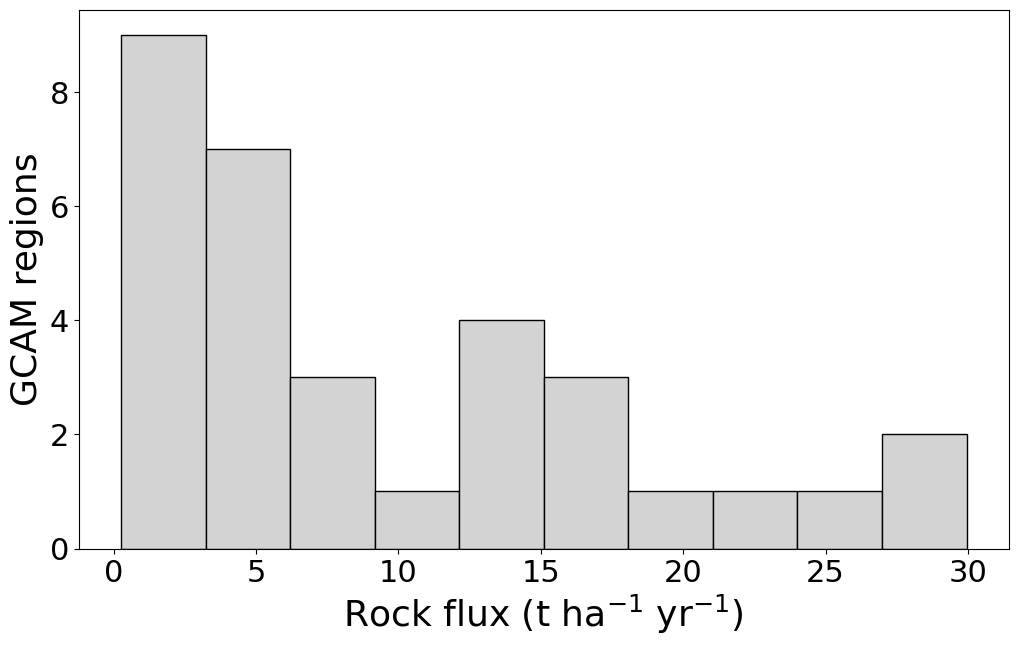

In [118]:
# ---------------------------------
# [ aesthetics ]
# color
barcol = 'lightgray'
barline = 'black'
# fontsize
fs_lab = 26
fs_ticks = 22
# ---------------------------------
# 
thiscase = 'exe_central1p5'
tdf = dfdict[thiscase]
last_time = tdf["time"].max()
df_last = tdf[tdf["time"] == last_time]

# [ plot ]
plt.figure(figsize=(12,7))
plt.hist(df_last['rockflx_t_ha'], color=barcol, edgecolor=barline)
plt.xlabel(r"Rock flux (t ha$^{-1}$ yr$^{-1}$)", fontsize=fs_lab)
plt.ylabel("GCAM regions", fontsize=fs_lab)
plt.tick_params(labelsize=fs_ticks)

## Plot ag map
[ copied from README ]
#### Summary
This repository is a simplified version of the complete repository global-agland-2015 that can be found at [https://doi.org/10.5281/zenodo.11540553](https://doi.org/10.5281/zenodo.11540553).

The complete version contains all code, input data, validation, and outputs, allowing users to fully reproduce the work and make adjustments for their own use cases.

This simplified version contains only the output files for global croplands and pastures.

The associated pre-print can be found at [https://doi.org/10.5194/essd-2024-279](https://doi.org/10.5194/essd-2024-279).


#### Methods summary
The data were constructed by combining subnational and national statistics on cropland and pasture area with land cover data from MODIS MCD12Q1 v6. A gradient boosting tree (GBT) model was used to predict the proportion of cropland, pasture and other in 5 arcminute grid cells. Some post-processing was done (i.e. GDD mask, aridity mask, water bodies, Antarctica). See the publication for full description of methods.

#### Data files
* [Cropland file](./output_3_cropland.tif)
* [Pasture file](./output_3_pasture.tif)
* [Other](./output_3_other.tif)

The data are presented in GeoTiff format.
  
Resolution: 5 arcminutes

Extent:-180, 180, -90, 90  (xmin, xmax, ymin, ymax)

CRS: EPSG:4326



#### Citation
```
Mehrabi, Z., Tong, K., Fortin, J., Stanimirova, R., Frield, M., and Ramankutty, N.: Geospatial database of global agricultural lands in the year 2015, Zenodo [dataset]. https://doi.org/10.5281/zenodo.11540554, 2024.
```

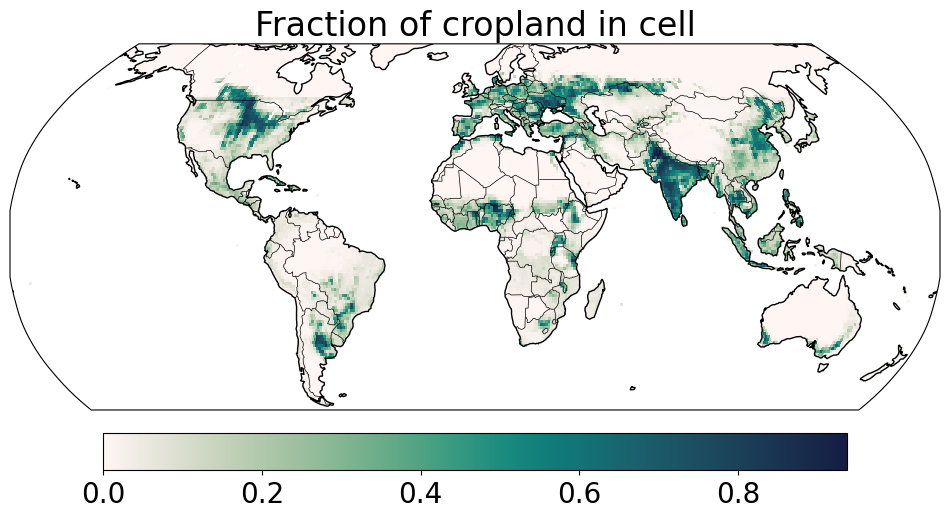

In [213]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cmo
# ---------------------------------
# [ aesthetics ]
# color
mycmap = cmo.cm.tempo
# fonts
fs_title = 24
fs_legend_tick = 20
fs_legend_title= 20 
# extent
lon_min = -181
lon_max = 181
lat_min = -57
lat_max = 70
# ---------------------------------
# --- remove ocean cells
dsag['cropland_frac_plot'] = dsag['cropland_frac'].where(dsag['cropland_area_by_region'] != 0, other=np.nan)

# --- [ PLOT ]
da = dsag['cropland_frac_plot']

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

# Plot (important: specify transform!)
im = da.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),  # data are lat/lon
    cmap= mycmap,
    add_colorbar=True,
    cbar_kwargs={
        "orientation": "horizontal",
        "pad": 0.05,        # distance from plot
        "shrink": 0.8       # optional: make shorter
    }
)
# colorbar text
cbar = im.colorbar
cbar.ax.tick_params(labelsize=fs_legend_tick)
cbar.set_label("", fontsize=fs_legend_title)
# extent + coasts
ax.set_extent([lon_min, lon_max, lat_min, lat_max],
              crs=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
# ax.set_global()
plt.title("Fraction of cropland in cell", fontsize= fs_title)
plt.show()


## Plot GCAM regions 

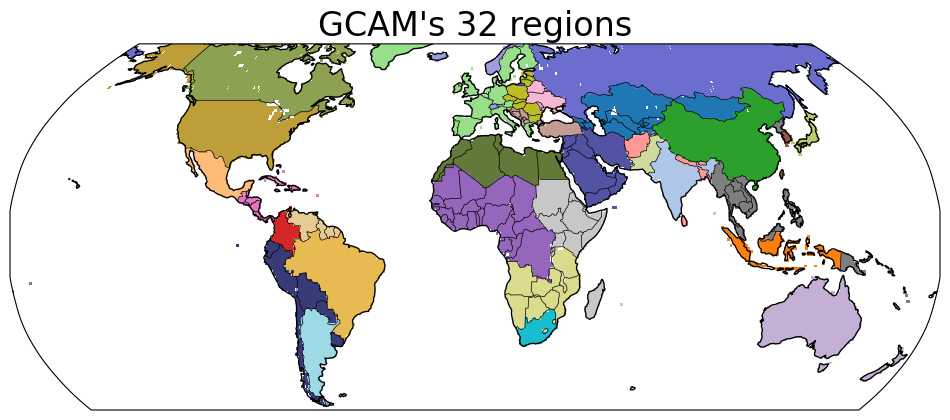

In [214]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cmo
import matplotlib.colors as mcolors
# ---------------------------------
# [ aesthetics ]
# color
mycmap = cmo.cm.tempo
# fonts
fs_title = 24
fs_legend_tick = 20
fs_legend_title= 20 
# extent
lon_min = -181
lon_max = 181
lat_min = -57
lat_max = 70
# ---------------------------------
# --- colors 
colors = list(
    plt.get_cmap("tab20").colors +
    plt.get_cmap("tab20b").colors
)
colors = colors[:32]   # ensure exactly 32
np.random.seed(42)     # reproducible shuffle
np.random.shuffle(colors)
cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(np.arange(0.5, 33.5, 1), cmap.N)

# --- remove ocean cells
dsag['reg_id_plot'] = dsag['reg_id'].where(dsag['cropland_area_by_region'] != 0, other=np.nan)

# --- [ PLOT ]
da = dsag['reg_id_plot']

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

# Plot (important: specify transform!)
im = da.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),  # data are lat/lon
    cmap= cmap,
    norm=norm,
    add_colorbar=False,
    # cbar_kwargs={
    #     "orientation": "horizontal",
    #     "pad": 0.05,        # distance from plot
    #     "shrink": 0.8       # optional: make shorter
    # }
)
# # colorbar text
# cbar = im.colorbar
# cbar.ax.tick_params(labelsize=fs_legend_tick)
# cbar.set_label("", fontsize=fs_legend_title)
# extent + coasts
ax.set_extent([lon_min, lon_max, lat_min, lat_max],
              crs=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
# ax.set_global()
plt.title("GCAM's 32 regions", fontsize= fs_title)
plt.show()


### CDF: Rock application, mass-weighted
CAUTION: this is funky to interpret, because the mass-weighting confounds the application flux..

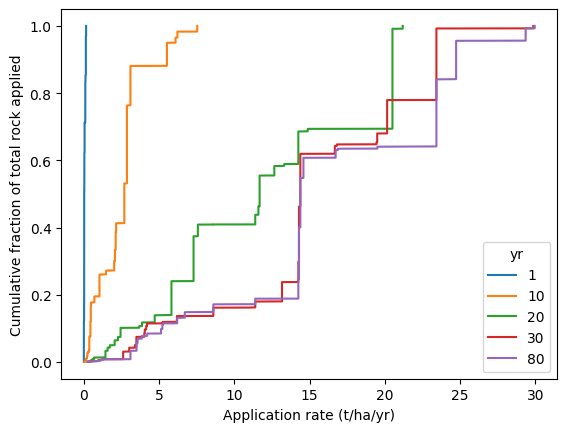

In [230]:
# dsag['rockflx_Mt'].isel(time=80).plot()
yrdx = [1, 10, 20, 30, 80]

for yr in yrdx:
    # Flatten and drop NaNs
    rate = dsag["rockflx_t_ha"].isel(time=yr).values.flatten()
    mass = dsag["rockflx_Mt"].isel(time=yr).values.flatten()

    mask = np.isfinite(rate) & np.isfinite(mass) & (mass > 0)

    rate = rate[mask]
    mass = mass[mask]

    # Sort by application rate
    sort_idx = np.argsort(rate)
    rate_sorted = rate[sort_idx]
    mass_sorted = mass[sort_idx]

    # Cumulative fraction of total rock applied
    cum_mass_frac = np.cumsum(mass_sorted) / np.sum(mass_sorted)

    # [ PLOT ]
    plt.plot(rate_sorted, cum_mass_frac, label=yr)
plt.xlabel("Application rate (t/ha/yr)")
plt.ylabel("Cumulative fraction of total rock applied")
# plt.ylim(0,1)
plt.legend(title="yr")
plt.show()

### CDF: Rock application, area-weighted

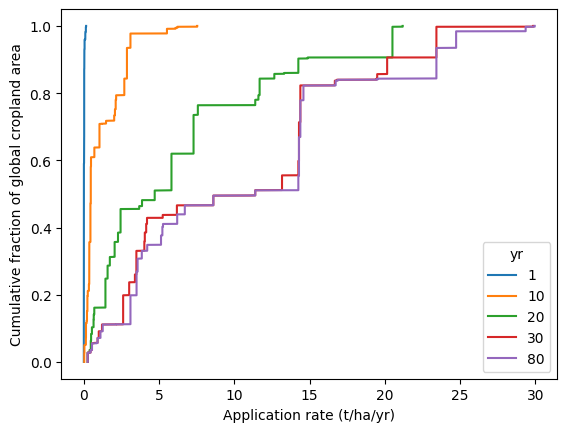

In [233]:
yrdx = [1, 10, 20, 30, 80]

for yr in yrdx:
    # Flatten arrays
    rate = dsag["rockflx_t_ha"].isel(time=yr).values.flatten()
    area = dsag["cropland_area"].values.flatten()

    # Keep only valid cropland cells
    mask = np.isfinite(rate) & np.isfinite(area) & (area > 0)

    rate = rate[mask]
    area = area[mask]

    # Sort by application rate
    sort_idx = np.argsort(rate)
    rate_sorted = rate[sort_idx]
    area_sorted = area[sort_idx]

    # Cumulative area fraction
    cum_area_frac = np.cumsum(area_sorted) / np.sum(area_sorted)
    # [ PLOT ]
    plt.plot(rate_sorted, cum_area_frac, label=yr)
plt.xlabel("Application rate (t/ha/yr)")
plt.ylabel("Cumulative fraction of global cropland area")
# plt.ylim(0,1)
plt.legend(title="yr")
plt.show()

# scratch ------

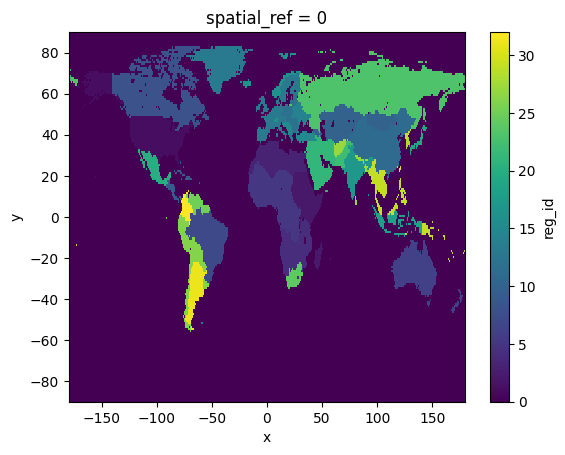

In [207]:
#
da.plot()

In [93]:
# ---
top3['region'].unique()

array(['China', 'India', 'USA'], dtype=object)

In [259]:
dfx = pd.read_csv('/Users/tylerkukla/Downloads/01092026_v2_df_out_CDR_QC.csv')
dfx[dfx['10_2_net_CDR_best_estimate_converted_v'] > 10]['1_1_author_short'].unique()

array(['Renforth et al. 2009', 'Cipolla et al.', 'Jorat et al.',
       'Pogge von Strandmann et al.', 'Wood et al.', 'Mühlbauer et al.',
       'Ryan et al.', 'Stubbs et al.'], dtype=object)

In [149]:
# dfx[dfx['10_2_net_CDR_best_estimate_converted_v'] > 1]['1_1_author_short'].unique()
dfx[dfx['1_1_author_short'] == "Wood et al."]#['10_2_net_CDR_best_estimate_converted_v']

,1_1_db_index,1_1_author_short,1_1_all_authors,1_1_year,1_1_journal_short,1_1_journal_long,1_1_first_author_location,1_1_peer_reviewed,1_1_keywords,1_1_doi_issn_isbn,...,11_needs_check,11_1_MRV_system_boundary,11_1_MRV_system_boundary_needs_check,11_2_in_field_losses,11_2_in_field_losses_comment,11_2_strong_acid_correction_method,11_2_strong_acid_correction_comment,11_2_downstream_losses_,11_2_downstream_losses_comment,11_2_losses_need_check
347,14596,Wood et al.,C. Wood; A.L. Harrison; I.M. Power,2023.0,AG,Applied Geochemistry,"Kingston, Canada",yes,"wollastonite, enhanced rock weathering, CO2 re...",10.1016/j.apgeochem.2022.105511,...,NaN,surface soil (10 cm),NaN,"ion exchange effects, secondary carboantes, cl...",CDR measured from effluent,NaN,NaN,NaN,NaN,NaN
348,14601,Wood et al.,C. Wood; A.L. Harrison; I.M. Power,2023.0,AG,Applied Geochemistry,"Kingston, Canada",yes,"wollastonite, enhanced rock weathering, CO2 re...",10.1016/j.apgeochem.2022.105511,...,NaN,surface soil (10 cm),NaN,"ion exchange effects, secondary carboantes, cl...",CDR measured from effluent,NaN,NaN,NaN,NaN,NaN
349,14616,Wood et al.,C. Wood; A.L. Harrison; I.M. Power,2023.0,AG,Applied Geochemistry,"Kingston, Canada",yes,"wollastonite, enhanced rock weathering, CO2 re...",10.1016/j.apgeochem.2022.105511,...,NaN,surface soil (10 cm),NaN,"ion exchange effects, secondary carboantes, cl...",CDR measured from effluent,NaN,NaN,NaN,NaN,NaN
350,14621,Wood et al.,C. Wood; A.L. Harrison; I.M. Power,2023.0,AG,Applied Geochemistry,"Kingston, Canada",yes,"wollastonite, enhanced rock weathering, CO2 re...",10.1016/j.apgeochem.2022.105511,...,NaN,surface soil (10 cm),NaN,"ion exchange effects, secondary carboantes, cl...",CDR measured from effluent,NaN,NaN,NaN,NaN,NaN


In [268]:
dfx[dfx['4_primary_type_harmonized_high_level'] == "model study"]['1_1_doi_issn_isbn'].unique()

array(['10.1073/pnas.1000545107', '10.1016/j.apgeochem.2021.105023',
       '10.1016/j.ijggc.2018.06.021', '10.1088/1748-9326/aaa9c4',
       '10.1016/j.advwatres.2021.103949', '10.1038/s41561-021-00798-x',
       '10.1016/j.jclepro.2021.128178', '10.5194/bg-19-3877-2022',
       '10.5194/gmd-15-4959-2022', '10.1038/s43247-022-00544-0',
       '10.3389/fclim.2022.928215', '10.1016/j.jclepro.2023.138914',
       '10.1029/2023EF003698', '10.1016/j.scitotenv.2023.165766',
       '10.1038/s41598-023-36113-4', '10.1016/j.apgeochem.2023.105643',
       '10.1016/j.apgeochem.2024.105940',
       '10.1109/ICUE63019.2024.10795542', '10.1039/d4ee03166k',
       '10.1029/2024MS004224'], dtype=object)